In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sameerml777/medical-cost-dataset/insurance.csv


In [2]:
df=pd.read_csv('/kaggle/input/datasets/sameerml777/medical-cost-dataset/insurance.csv')

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [4]:
df.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [5]:
df['region'].nunique()

4

In [6]:
from sklearn.preprocessing import LabelEncoder

In [7]:
le=LabelEncoder()
df['sex']=le.fit_transform(df['sex'])
df['smoker']=le.fit_transform(df['smoker'])
df=pd.get_dummies(df,columns=['region'],dtype=int)

In [8]:
df.corr(numeric_only=True)

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
age,1.000000,-0.020856,0.109272,0.042469,-0.025019,0.299008,0.002475,-0.000407,-0.011642,0.010016
sex,-0.020856,1.000000,0.046371,0.017163,0.076185,0.057292,-0.002425,-0.011156,0.017117,-0.004184
bmi,0.109272,0.046371,1.000000,0.012759,0.003750,0.198341,-0.138156,-0.135996,0.270025,-0.006205
children,0.042469,0.017163,0.012759,1.000000,0.007673,0.067998,-0.022808,0.024806,-0.023066,0.021914
smoker,-0.025019,0.076185,0.003750,0.007673,1.000000,0.787251,0.002811,-0.036945,0.068498,-0.036945
charges,0.299008,0.057292,0.198341,0.067998,0.787251,1.000000,0.006349,-0.039905,0.073982,-0.043210
region_northeast,0.002475,-0.002425,-0.138156,-0.022808,0.002811,0.006349,1.000000,-0.320177,-0.345561,-0.320177
region_northwest,-0.000407,-0.011156,-0.135996,0.024806,-0.036945,-0.039905,-0.320177,1.000000,-0.346265,-0.320829
region_southeast,-0.011642,0.017117,0.270025,-0.023066,0.068498,0.073982,-0.345561,-0.346265,1.000000,-0.346265
region_southwest,0.010016,-0.004184,-0.006205,0.021914,-0.036945,-0.043210,-0.320177,-0.320829,-0.346265,1.000000


In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

<Axes: xlabel='sex', ylabel='charges'>

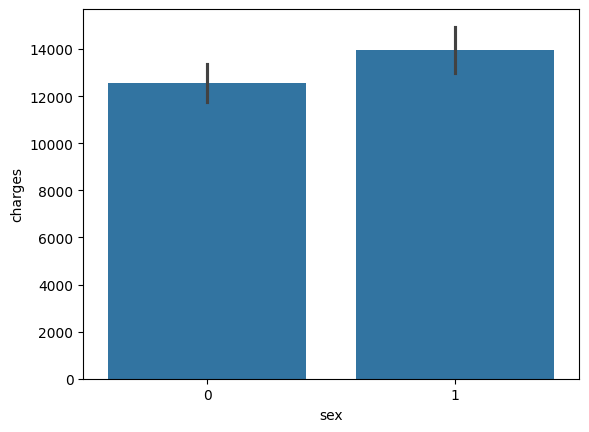

In [10]:
sns.barplot(df,x='sex',y='charges')

<Axes: xlabel='bmi', ylabel='charges'>

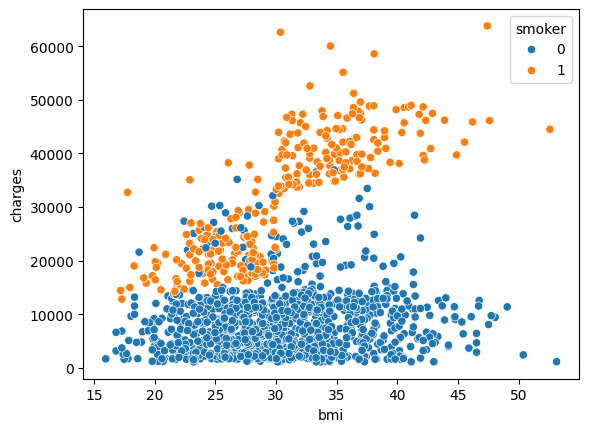

In [11]:
sns.scatterplot(df,x='bmi',y='charges',hue='smoker')

<Axes: xlabel='smoker', ylabel='charges'>

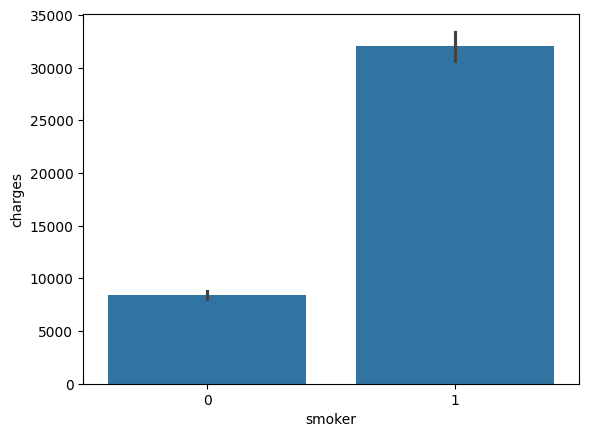

In [12]:
sns.barplot(df,x='smoker',y='charges')

In [13]:
df = df[(df['charges'] <= 55000) & (df['bmi'] <= 50)]
print(df.shape)  


(1330, 10)


<Axes: xlabel='bmi', ylabel='charges'>

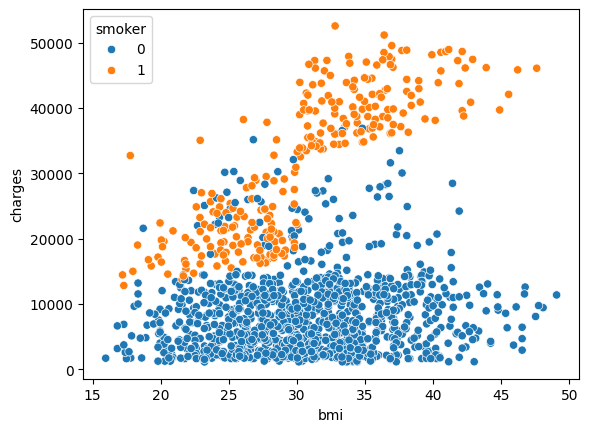

In [14]:
sns.scatterplot(df,x='bmi',y='charges',hue='smoker')

In [15]:
df

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,0,27.900,0,1,16884.92400,0,0,0,1
1,18,1,33.770,1,0,1725.55230,0,0,1,0
2,28,1,33.000,3,0,4449.46200,0,0,1,0
3,33,1,22.705,0,0,21984.47061,0,1,0,0
4,32,1,28.880,0,0,3866.85520,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
1333,50,1,30.970,3,0,10600.54830,0,1,0,0
1334,18,0,31.920,0,0,2205.98080,1,0,0,0
1335,18,0,36.850,0,0,1629.83350,0,0,1,0
1336,21,0,25.800,0,0,2007.94500,0,0,0,1


In [16]:
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()
df['age']=sc.fit_transform(df[['age']])
df['charges']=sc.fit_transform(df[['charges']])
df['bmi']=sc.fit_transform(df[['bmi']])


In [17]:
df

,age,sex,bmi,children,smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,-1.440545,0,-0.448054,0,1,0.322934,0,0,0,1
1,-1.511740,1,0.529409,1,0,-0.966543,0,0,1,0
2,-0.799791,1,0.401190,3,0,-0.734844,0,0,1,0
3,-0.443817,1,-1.313117,0,0,0.756708,0,1,0,0
4,-0.515012,1,-0.284866,0,0,-0.784401,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
1333,0.766496,1,0.063157,3,0,-0.211624,0,1,0,0
1334,-1.511740,0,0.221350,0,0,-0.925677,1,0,0,0
1335,-1.511740,0,1.042286,0,0,-0.974685,0,0,1,0
1336,-1.298155,0,-0.797743,0,0,-0.942523,0,0,0,1


In [18]:
x=df.drop(columns='charges')
y=df['charges']

In [19]:
from sklearn.svm import SVR
from sklearn.model_selection import  cross_val_score

model_svr=SVR(kernel='rbf',C=1)
score=cross_val_score(model_svr,x,y,cv=5)


In [20]:
score

array([0.87029158, 0.80016766, 0.86134181, 0.81649707, 0.84711863])

In [21]:
ans=score.mean()
ans

np.float64(0.8390833516187695)

Model: (SVR or linear)
Features: the 6 original columns, encoded
Filter: charges <= 55000 and bmi <= 50 (if you kept it)
Score: R² ≈ 0.84